In [1]:
import os
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity as ssim
from sklearn.model_selection import train_test_split

In [2]:
# Ablation configuration
from pathlib import Path

DATA_ROOT = "/Users/rishab/Research"
TARGET_FOLDER = "IR_drop"
ACTIVE_INPUTS = ['power_s']
CHANNELS_BY_INPUT = {
    "power_all": 1,
    "power_i": 1,
    "power_sca": 1,
    "power_s": 1,
    "power_t": 20,
}
INPUT_CHANNELS = sum(CHANNELS_BY_INPUT[name] for name in ACTIVE_INPUTS)

TARGET_SIZE = (320, 320)
BATCH_SIZE = 16
RUN_ID = "only_ps"
RUN_DIR = Path("artifacts") / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = str(RUN_DIR / f"best_{RUN_ID}.keras")
FINAL_MODEL_PATH = str(RUN_DIR / f"final_{RUN_ID}.keras")
RESULTS_CSV = "fpn_ablation_results.csv"

print("Run:", RUN_ID)
print("Active inputs:", ACTIVE_INPUTS)
print("Input channels:", INPUT_CHANNELS)


Run: only_ps
Active inputs: ['power_s']
Input channels: 1


In [3]:
def load_input_array(path, input_name):
    arr_file = np.load(path)
    if isinstance(arr_file, np.lib.npyio.NpzFile):
        arr = list(arr_file.values())[0]
        arr_file.close()
    else:
        arr = arr_file
    arr = arr.astype(np.float32)

    if input_name == "power_t":
        if arr.ndim == 3 and arr.shape[0] == 20:
            arr = np.transpose(arr, (1, 2, 0))
    elif arr.ndim == 2:
        arr = arr[..., np.newaxis]

    return arr


def compute_channel_min_max(file_list):
    channel_min = None
    channel_max = None

    for rel_path in file_list:
        chip = rel_path.split(os.sep)[0]
        filename = rel_path.split(os.sep)[-1]
        power_maps = [
            load_input_array(os.path.join(DATA_ROOT, chip, name, filename), name)
            for name in ACTIVE_INPUTS
        ]
        X = np.concatenate(power_maps, axis=-1)
        sample_min = X.min(axis=(0, 1))
        sample_max = X.max(axis=(0, 1))

        if channel_min is None:
            channel_min = sample_min
            channel_max = sample_max
        else:
            channel_min = np.minimum(channel_min, sample_min)
            channel_max = np.maximum(channel_max, sample_max)

    return channel_min, channel_max


In [4]:
# ----------------------------
# File split (identical seed and targets in every ablation)
# ----------------------------
CHIPS = [
    "Vortex-small",
    # "Vortex-large",
    # "nvdla-large",
    "nvdla-small",
    "openc910-1",
    "RISCY",
    "RISCY-FPU",
    "zero-riscy",
]

all_files = []
chip_names = []

for chip in CHIPS:
    ir_dir = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)
    for f in sorted(os.listdir(ir_dir)):
        if all(os.path.exists(os.path.join(DATA_ROOT, chip, name, f)) for name in ACTIVE_INPUTS):
            all_files.append(os.path.join(chip, TARGET_FOLDER, f))
            chip_names.append(chip)

train_files, temp_files, train_labels, temp_labels = train_test_split(
    all_files, chip_names, test_size=0.2, random_state=42, stratify=chip_names
)
val_files, test_files, val_labels, test_labels = train_test_split(
    temp_files, temp_labels, test_size=0.5, random_state=42, stratify=temp_labels
)

CHANNEL_MIN, CHANNEL_MAX = compute_channel_min_max(train_files)
CHANNEL_MIN_TF = tf.constant(CHANNEL_MIN, dtype=tf.float32)
CHANNEL_MAX_TF = tf.constant(CHANNEL_MAX, dtype=tf.float32)

print("CHANNEL_MIN:", CHANNEL_MIN)
print("CHANNEL_MAX:", CHANNEL_MAX)


CHANNEL_MIN: [0.]
CHANNEL_MAX: [240.45189]


2026-08-09 10:36:57.513880: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5 Pro
2026-08-09 10:36:57.513902: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 48.00 GB
2026-08-09 10:36:57.513906: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 18.72 GB
I0000 00:00:1786297017.514103 23085882 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1786297017.514243 23085882 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [5]:
for chip in CHIPS:
    path = os.path.join(DATA_ROOT, chip, TARGET_FOLDER)
    print(chip, len(os.listdir(path)))

Vortex-small 96
nvdla-small 85
openc910-1 96
RISCY 3170
RISCY-FPU 3456
zero-riscy 3456


In [6]:
for chip in CHIPS:
    vals = []

    chip_files = [f for f in all_files if f.startswith(chip)]

    for rel in chip_files:
        arr = np.load(os.path.join(DATA_ROOT, rel))
        if isinstance(arr, np.lib.npyio.NpzFile):
            arr = list(arr.values())[0]
        vals.append(arr.max())

    print(chip, np.max(vals), np.mean(vals))

Vortex-small 1386.04 349.9682604166666
nvdla-small 1038.36 369.0019058823529
openc910-1 2628.57 387.2102958333333
RISCY 1230.39 130.62924868699065
RISCY-FPU 1230.39 138.82606987847223
zero-riscy 605.268 118.03035561342594


In [7]:
# ----------------------------
# STEP 2: Dataset loader with channel-wise normalization
# ----------------------------
def load_npy(path):
    def _load(path):
        arr_file = np.load(path.decode("utf-8"))
        if isinstance(arr_file, np.lib.npyio.NpzFile):
            arr = list(arr_file.values())[0]
        else:
            arr = arr_file
        arr = arr.astype(np.float32)
        if arr.ndim == 2:
            arr = arr[..., np.newaxis]
        return arr

    tensor = tf.numpy_function(_load, [path], tf.float32)
    tensor.set_shape([None, None, None])
    tensor = tf.image.resize(tensor, TARGET_SIZE)
    return tensor

In [8]:
def load_sample(rel_path):
    y_path = tf.strings.join([DATA_ROOT, rel_path], separator=os.sep)
    y = load_npy(y_path)

    chip = tf.strings.split(rel_path, os.sep)[0]
    filename = tf.strings.split(rel_path, os.sep)[-1]
    power_maps = []

    for input_name in ACTIVE_INPUTS:
        x_path = tf.strings.join([DATA_ROOT, chip, input_name, filename], separator=os.sep)

        def _load_active(path, name=input_name):
            return load_input_array(path.decode("utf-8"), name)

        x = tf.numpy_function(_load_active, [x_path], tf.float32)
        x.set_shape([None, None, CHANNELS_BY_INPUT[input_name]])
        x = tf.image.resize(x, TARGET_SIZE)
        power_maps.append(x)

    X = tf.concat(power_maps, axis=-1)
    X.set_shape([TARGET_SIZE[0], TARGET_SIZE[1], INPUT_CHANNELS])
    X = (X - CHANNEL_MIN_TF) / (CHANNEL_MAX_TF - CHANNEL_MIN_TF + 1e-8)
    return X, y


In [9]:
# ----------------------------
# STEP 3: Build datasets
# ----------------------------
train_dataset = (
    tf.data.Dataset.from_tensor_slices(train_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(len(train_files))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_dataset = (
    tf.data.Dataset.from_tensor_slices(val_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_dataset = (
    tf.data.Dataset.from_tensor_slices(test_files)
    .map(load_sample, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [10]:
def compute_global_max(dataset):
    global_max = 0.0

    for _, y_batch in dataset:
        batch_max = tf.reduce_max(y_batch)
        global_max = max(global_max, float(batch_max))

    return global_max

train_max = compute_global_max(train_dataset)
val_max   = compute_global_max(val_dataset)
test_max  = compute_global_max(test_dataset)

print("Train max:", train_max)
print("Val max:", val_max)
print("Test max:", test_max)

2026-08-09 10:37:14.969904: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-08-09 10:37:16.053577: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Train max: 2417.285888671875
Val max: 2418.465087890625
Test max: 770.0360717773438


In [11]:
print("Train:", len(train_files))
print("Val:", len(val_files))
print("Test:", len(test_files))

for X, y in train_dataset.take(1):
    print("X:", X.shape)  # (B, 300, 300, 24)
    print("y:", y.shape)  # (B, 300, 300, 1)

Train: 8287
Val: 1036
Test: 1036
X: (16, 320, 320, 1)
y: (16, 320, 320, 1)


2026-08-09 10:37:22.517764: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


In [12]:
import time


# =========================================================
# BASIC CONVOLUTION BLOCK
# =========================================================

def conv_block(x, filters, name, strides=1):
    x = layers.Conv2D(
        filters,
        kernel_size=3,
        strides=strides,
        padding="same",
        use_bias=False,
        name=f"{name}_conv1"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn1")(x)
    x = layers.Activation("relu", name=f"{name}_relu1")(x)

    x = layers.Conv2D(
        filters,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name=f"{name}_conv2"
    )(x)
    x = layers.BatchNormalization(name=f"{name}_bn2")(x)
    x = layers.Activation("relu", name=f"{name}_relu2")(x)

    return x


# =========================================================
# FPN MODEL
# =========================================================

def build_fpn(
    input_shape=(320, 320, INPUT_CHANNELS),
    pyramid_filters=128
):
    inputs = layers.Input(shape=input_shape, name="input")

    # -----------------------------------------------------
    # Bottom-up encoder
    # -----------------------------------------------------

    # C1: 320 × 320
    c1 = conv_block(inputs, 32, name="c1")

    # C2: 160 × 160
    c2 = conv_block(c1, 64, name="c2", strides=2)

    # C3: 80 × 80
    c3 = conv_block(c2, 128, name="c3", strides=2)

    # C4: 40 × 40
    c4 = conv_block(c3, 256, name="c4", strides=2)

    # C5: 20 × 20
    c5 = conv_block(c4, 512, name="c5", strides=2)

    # -----------------------------------------------------
    # Lateral 1×1 projections
    # -----------------------------------------------------

    lateral_c2 = layers.Conv2D(
        pyramid_filters,
        kernel_size=1,
        padding="same",
        name="c2_lateral"
    )(c2)

    lateral_c3 = layers.Conv2D(
        pyramid_filters,
        kernel_size=1,
        padding="same",
        name="c3_lateral"
    )(c3)

    lateral_c4 = layers.Conv2D(
        pyramid_filters,
        kernel_size=1,
        padding="same",
        name="c4_lateral"
    )(c4)

    lateral_c5 = layers.Conv2D(
        pyramid_filters,
        kernel_size=1,
        padding="same",
        name="c5_lateral"
    )(c5)

    # -----------------------------------------------------
    # Top-down feature pyramid
    # -----------------------------------------------------

    # P5: 20 × 20
    p5 = lateral_c5

    # P4: 40 × 40
    p5_up = layers.UpSampling2D(
        size=2,
        interpolation="bilinear",
        name="p5_upsample"
    )(p5)

    p4 = layers.Add(name="p4_add")([
        lateral_c4,
        p5_up
    ])

    # P3: 80 × 80
    p4_up = layers.UpSampling2D(
        size=2,
        interpolation="bilinear",
        name="p4_upsample"
    )(p4)

    p3 = layers.Add(name="p3_add")([
        lateral_c3,
        p4_up
    ])

    # P2: 160 × 160
    p3_up = layers.UpSampling2D(
        size=2,
        interpolation="bilinear",
        name="p3_upsample"
    )(p3)

    p2 = layers.Add(name="p2_add")([
        lateral_c2,
        p3_up
    ])

    # -----------------------------------------------------
    # Standard 3×3 smoothing convolutions
    # -----------------------------------------------------

    p2 = layers.Conv2D(
        pyramid_filters,
        kernel_size=3,
        padding="same",
        name="p2_smooth"
    )(p2)

    p3 = layers.Conv2D(
        pyramid_filters,
        kernel_size=3,
        padding="same",
        name="p3_smooth"
    )(p3)

    p4 = layers.Conv2D(
        pyramid_filters,
        kernel_size=3,
        padding="same",
        name="p4_smooth"
    )(p4)

    p5 = layers.Conv2D(
        pyramid_filters,
        kernel_size=3,
        padding="same",
        name="p5_smooth"
    )(p5)

    # -----------------------------------------------------
    # Bring every pyramid level to full resolution
    # -----------------------------------------------------

    p2_full = layers.UpSampling2D(
        size=2,
        interpolation="bilinear",
        name="p2_to_full"
    )(p2)

    p3_full = layers.UpSampling2D(
        size=4,
        interpolation="bilinear",
        name="p3_to_full"
    )(p3)

    p4_full = layers.UpSampling2D(
        size=8,
        interpolation="bilinear",
        name="p4_to_full"
    )(p4)

    p5_full = layers.UpSampling2D(
        size=16,
        interpolation="bilinear",
        name="p5_to_full"
    )(p5)

    # Combine information from all pyramid levels.
    x = layers.Concatenate(name="pyramid_fusion")([
        p2_full,
        p3_full,
        p4_full,
        p5_full
    ])

    # -----------------------------------------------------
    # Dense regression head
    # -----------------------------------------------------

    x = layers.Conv2D(
        128,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name="regression_conv1"
    )(x)
    x = layers.BatchNormalization(name="regression_bn1")(x)
    x = layers.Activation("relu", name="regression_relu1")(x)

    x = layers.Conv2D(
        64,
        kernel_size=3,
        padding="same",
        use_bias=False,
        name="regression_conv2"
    )(x)
    x = layers.BatchNormalization(name="regression_bn2")(x)
    x = layers.Activation("relu", name="regression_relu2")(x)

    outputs = layers.Conv2D(
        1,
        kernel_size=1,
        padding="same",
        activation="linear",
        name="ir_drop"
    )(x)

    return models.Model(
        inputs=inputs,
        outputs=outputs,
        name="vanilla_fpn_ir_drop"
    )


model = build_fpn()
model.summary()

# Optional smoke test
assert model.input_shape == (None, 320, 320, INPUT_CHANNELS)
assert model.output_shape == (None, 320, 320, 1)

Model: "vanilla_fpn_ir_drop"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 320, 320,  │          0 │ -                 │
│                     │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_conv1 (Conv2D)   │ (None, 320, 320,  │        288 │ input[0][0]       │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_bn1              │ (None, 320, 320,  │        128 │ c1_conv1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_relu1            │ (None, 320, 320,  │          0 │ c1_bn1[0][0]      │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_conv2 (Conv2D)   │ (None, 320, 320,  │      9,216 │ c1_relu1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_bn2              │ (None, 320, 320,  │        128 │ c1_conv2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c1_relu2            │ (None, 320, 320,  │          0 │ c1_bn2[0][0]      │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_conv1 (Conv2D)   │ (None, 160, 160,  │     18,432 │ c1_relu2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_bn1              │ (None, 160, 160,  │        256 │ c2_conv1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_relu1            │ (None, 160, 160,  │          0 │ c2_bn1[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_conv2 (Conv2D)   │ (None, 160, 160,  │     36,864 │ c2_relu1[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_bn2              │ (None, 160, 160,  │        256 │ c2_conv2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c2_relu2            │ (None, 160, 160,  │          0 │ c2_bn2[0][0]      │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c3_conv1 (Conv2D)   │ (None, 80, 80,    │     73,728 │ c2_relu2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c3_bn1              │ (None, 80, 80,    │        512 │ c3_conv1[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c3_relu1            │ (None, 80, 80,    │          0 │ c3_bn1[0][0]      │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ c3_conv2 (Conv2D)   │ (None, 80, 80,    │    147,456 │ c3_relu1[0][0]  

 Total params: 6,095,713 (23.25 MB)

 Trainable params: 6,091,361 (23.24 MB)

 Non-trainable params: 4,352 (17.00 KB)

In [13]:
# =========================================================
# TIMER CALLBACK
# =========================================================

class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.time() - self.epoch_start_time
        self.times.append(elapsed)
        print(f"\nEpoch {epoch + 1} took {elapsed:.2f} seconds ({elapsed / 60:.2f} minutes)")


time_callback = TimeHistory()
total_start = time.time()


# =========================================================
# CALLBACKS
# =========================================================

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    CHECKPOINT_PATH,
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)


# =========================================================
# TRAINING
# =========================================================

print("\n========================================")
print("TRAINING FPN FROM SCRATCH")
print("========================================\n")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",
    metrics=["mae"]
)

train_start = time.time()

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=20,
    callbacks=[
        early_stop,
        reduce_lr,
        checkpoint,
        time_callback
    ]
)

train_end = time.time()

model.load_weights(CHECKPOINT_PATH)
model.save(FINAL_MODEL_PATH)

total_end = time.time()
total_seconds = total_end - total_start

print("\n========================================")
print("FPN TRAINING COMPLETE")
print("========================================")
print(f"Training time: {(train_end - train_start):.2f} seconds")
print(f"Training time: {(train_end - train_start) / 60:.2f} minutes")
print(f"Average epoch time: {sum(time_callback.times) / len(time_callback.times):.2f} seconds")
print(f"Total runtime: {total_seconds:.2f} seconds")
print(f"Total runtime: {total_seconds / 60:.2f} minutes")
print(f"Total runtime: {total_seconds / 3600:.2f} hours")


TRAINING FPN FROM SCRATCH

Epoch 1/20


/opt/anaconda3/envs/ml-metal/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-08-09 10:37:24.426270: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 103.1872 - mae: 4.5172
Epoch 1: val_loss improved from None to 7072.18652, saving model to artifacts/only_ps/best_only_ps.keras

Epoch 1: finished saving model to artifacts/only_ps/best_only_ps.keras

Epoch 1 took 1168.79 seconds (19.48 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1169s 2s/step - loss: 103.1872 - mae: 4.5172 - val_loss: 7072.1865 - val_mae: 81.2410 - learning_rate: 0.0010
Epoch 2/20
518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 92.0333 - mae: 4.1893
Epoch 2: val_loss improved from 7072.18652 to 118.43627, saving model to artifacts/only_ps/best_only_ps.keras

Epoch 2: finished saving model to artifacts/only_ps/best_only_ps.keras

Epoch 2 took 1157.52 seconds (19.29 minutes)
518/518 ━━━━━━━━━━━━━━━━━━━━ 1158s 2s/step - loss: 92.0333 - mae: 4.1893 - val_loss: 118.4363 - val_mae: 4.3681 - learning_rate: 0.0010
Epoch 3/20
518/518 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - loss: 81.9701 - mae: 3.7853
Epoch 3: val_loss did not improve from 11

In [14]:
# Evaluate on train, val, test
train_metrics = model.evaluate(train_dataset)
val_metrics   = model.evaluate(val_dataset)
test_metrics  = model.evaluate(test_dataset)

print("Train metrics (loss, MAE):", train_metrics)
print("Val metrics (loss, MAE):", val_metrics)
print("Test metrics (loss, MAE):", test_metrics)

518/518 ━━━━━━━━━━━━━━━━━━━━ 201s 374ms/step - loss: 63.3942 - mae: 3.4878
65/65 ━━━━━━━━━━━━━━━━━━━━ 25s 382ms/step - loss: 75.3658 - mae: 3.5488
65/65 ━━━━━━━━━━━━━━━━━━━━ 24s 374ms/step - loss: 62.4825 - mae: 3.5546
Train metrics (loss, MAE): [63.394187927246094, 3.487813711166382]
Val metrics (loss, MAE): [75.3658218383789, 3.548828601837158]
Test metrics (loss, MAE): [62.48245620727539, 3.5545690059661865]


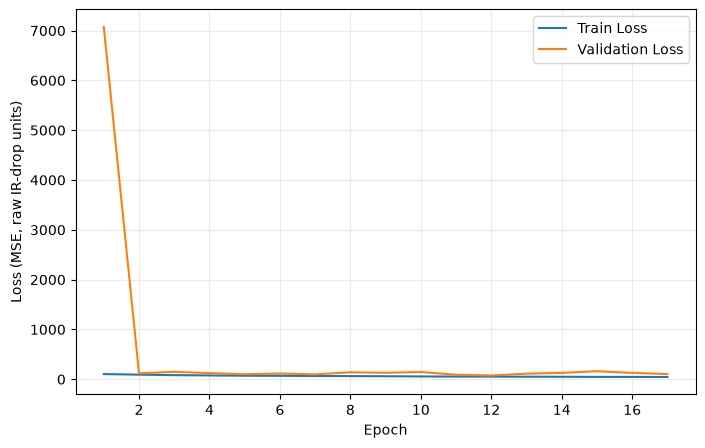

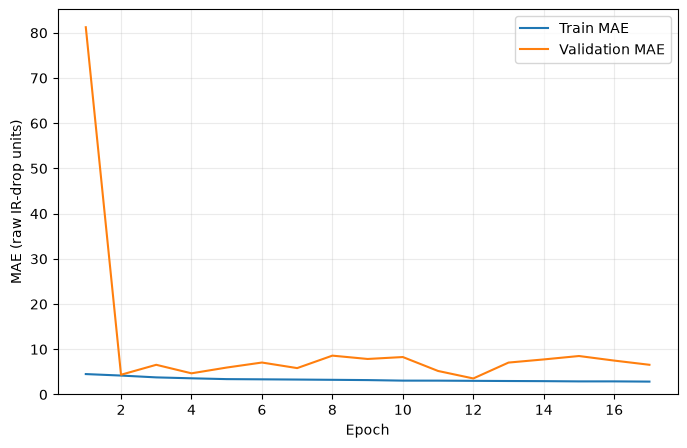

In [15]:
train_loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(train_loss) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE, raw IR-drop units)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

train_mae = history.history["mae"]
val_mae = history.history["val_mae"]

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_mae, label="Train MAE")
plt.plot(epochs, val_mae, label="Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE (raw IR-drop units)")
plt.legend()
plt.ylim(bottom=0)
plt.grid(alpha=0.25)
plt.show()

In [16]:
# =========================================================
# RAW-Y METRICS BLOCK
# Use for:
#   fft-strat-all.ipynb
#   fft-strat-all-no_outliers.ipynb
#
# This prints:
#   1. Combined metrics:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   2. Equal-weight chip average:
#        - global/test-set range
#        - per-chip range
#        - per-image range
#   3. Each chip:
#        - global/test-set range
#        - per-chip range
#        - per-image range
# =========================================================

chip_results = {}
all_preds = []
all_truth = []
all_chips = []

# -----------------------------
# Collect predictions grouped by chip
# -----------------------------
for batch_idx, (x_batch, y_batch) in enumerate(test_dataset):

    preds = model.predict(x_batch, verbose=0)

    batch_size = preds.shape[0]

    start_idx = batch_idx * BATCH_SIZE
    end_idx = start_idx + batch_size

    batch_files = test_files[start_idx:end_idx]

    for i in range(batch_size):

        chip = batch_files[i].split(os.sep)[0]

        pred = preds[i]
        truth = y_batch[i].numpy()

        if chip not in chip_results:
            chip_results[chip] = {
                "preds": [],
                "truth": []
            }

        chip_results[chip]["preds"].append(pred)
        chip_results[chip]["truth"].append(truth)

        all_preds.append(pred)
        all_truth.append(truth)
        all_chips.append(chip)


# =========================================================
# Helper functions
# =========================================================

def flatten_arrays(arrays):
    return np.array(arrays).flatten()


def get_range_from_arrays(arrays):
    arrays = np.array(arrays)
    return float(arrays.max() - arrays.min())


def compute_base_metrics(preds, truth):
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    mae = np.mean(np.abs(pred_flat - truth_flat))
    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    max_ir = truth_flat.max()

    nmae = mae / (max_ir + 1e-8)
    rrmse = rmse / (max_ir + 1e-8)

    maxe = np.max(np.abs(pred_flat - truth_flat))

    ss_res = np.sum((truth_flat - pred_flat) ** 2)
    ss_tot = np.sum((truth_flat - np.mean(truth_flat)) ** 2)

    if ss_tot == 0:
        r2 = np.nan
    else:
        r2 = 1 - (ss_res / ss_tot)

    return mae, nmae, rmse, rrmse, maxe, r2


def compute_ssim_psnr_global_range(preds, truth, global_data_range):
    # Uses ONE data range for everything.
    # For combined metrics, this matches your old global/test-set range idea.
    preds = np.array(preds)
    truth = np.array(truth)

    pred_flat = preds.flatten()
    truth_flat = truth.flatten()

    rmse = np.sqrt(np.mean((pred_flat - truth_flat) ** 2))

    psnr = 20 * np.log10(global_data_range / (rmse + 1e-8))

    ssim_vals = tf.image.ssim(
        tf.convert_to_tensor(truth, dtype=tf.float32),
        tf.convert_to_tensor(preds, dtype=tf.float32),
        max_val=global_data_range
    ).numpy()

    return np.mean(ssim_vals), psnr


def compute_ssim_psnr_single_group_range(preds, truth):
    # Uses the range of the passed-in group.
    # If the group is one chip, this is per-chip range.
    # If the group is all test samples, this is global/test-set range.
    data_range = get_range_from_arrays(truth)

    return compute_ssim_psnr_global_range(
        preds,
        truth,
        data_range
    )


def compute_ssim_psnr_per_chip_range(preds, truth, chips):
    # Uses each chip's own data range.
    # For combined metrics, each image is evaluated using its chip's range.
    # For one-chip metrics, this becomes the same as that chip's group range.
    preds = np.array(preds)
    truth = np.array(truth)
    chips = np.array(chips)

    ssim_vals = []
    psnr_vals = []

    for chip in np.unique(chips):

        idx = np.where(chips == chip)[0]

        chip_preds = preds[idx]
        chip_truth = truth[idx]

        chip_range = get_range_from_arrays(chip_truth)

        if chip_range <= 0:
            continue

        chip_ssim_vals = tf.image.ssim(
            tf.convert_to_tensor(chip_truth, dtype=tf.float32),
            tf.convert_to_tensor(chip_preds, dtype=tf.float32),
            max_val=chip_range
        ).numpy()

        chip_rmse = np.sqrt(np.mean((chip_preds - chip_truth) ** 2))
        chip_psnr = 20 * np.log10(chip_range / (chip_rmse + 1e-8))

        ssim_vals.extend(list(chip_ssim_vals))
        psnr_vals.extend([chip_psnr] * len(idx))

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_ssim_psnr_per_image_range(preds, truth):
    # Uses each image's own data range.
    # This is the strictest SSIM/PSNR version.
    preds = np.array(preds)
    truth = np.array(truth)

    ssim_vals = []
    psnr_vals = []

    for p, t in zip(preds, truth):

        image_range = float(t.max() - t.min())

        if image_range <= 0:
            continue

        ssim_val = tf.image.ssim(
            tf.convert_to_tensor(t[None, ...], dtype=tf.float32),
            tf.convert_to_tensor(p[None, ...], dtype=tf.float32),
            max_val=image_range
        ).numpy()[0]

        image_rmse = np.sqrt(np.mean((p - t) ** 2))
        image_psnr = 20 * np.log10(image_range / (image_rmse + 1e-8))

        ssim_vals.append(ssim_val)
        psnr_vals.append(image_psnr)

    return np.mean(ssim_vals), np.mean(psnr_vals)


def compute_metrics(preds, truth, chips, range_mode, global_data_range=None):
    mae, nmae, rmse, rrmse, maxe, r2 = compute_base_metrics(preds, truth)

    if range_mode == "global":
        ssim_score, psnr = compute_ssim_psnr_global_range(
            preds,
            truth,
            global_data_range
        )

    elif range_mode == "per_chip":
        ssim_score, psnr = compute_ssim_psnr_per_chip_range(
            preds,
            truth,
            chips
        )

    elif range_mode == "per_image":
        ssim_score, psnr = compute_ssim_psnr_per_image_range(
            preds,
            truth
        )

    else:
        raise ValueError("range_mode must be 'global', 'per_chip', or 'per_image'")

    return {
        "SSIM": ssim_score,
        "MAE": mae,
        "NMAE": nmae,
        "RMSE": rmse,
        "rRMSE": rrmse,
        "MaxE": maxe,
        "PSNR": psnr,
        "R2": r2
    }


def print_metrics(title, metrics):
    print("\n==============================")
    print(title)
    print("==============================")

    for k, v in metrics.items():
        print(f"{k:8}: {v:.6f}")


# =========================================================
# Global/test-set range
# =========================================================

global_data_range = get_range_from_arrays(all_truth)

print("\n============================================================")
print("GLOBAL / TEST-SET DATA RANGE")
print("============================================================")
print(f"Global data range: {global_data_range:.6f}")


# =========================================================
# 1. Combined metrics
# =========================================================

combined_global = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="global",
    global_data_range=global_data_range
)

combined_per_chip = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_chip",
    global_data_range=global_data_range
)

combined_per_image = compute_metrics(
    all_preds,
    all_truth,
    all_chips,
    range_mode="per_image",
    global_data_range=global_data_range
)

print_metrics("COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE", combined_global)
print_metrics("COMBINED TEST METRICS - PER-CHIP RANGE", combined_per_chip)
print_metrics("COMBINED TEST METRICS - PER-IMAGE RANGE", combined_per_image)


# =========================================================
# 2. Equal-weight chip averages
# =========================================================

per_chip_metrics_global = {}
per_chip_metrics_per_chip = {}
per_chip_metrics_per_image = {}

for chip in CHIPS:

    chip_preds = chip_results[chip]["preds"]
    chip_truth = chip_results[chip]["truth"]
    chip_labels = [chip] * len(chip_preds)

    per_chip_metrics_global[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="global",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_chip[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_chip",
        global_data_range=global_data_range
    )

    per_chip_metrics_per_image[chip] = compute_metrics(
        chip_preds,
        chip_truth,
        chip_labels,
        range_mode="per_image",
        global_data_range=global_data_range
    )


def compute_equal_weight_average(per_chip_metrics):
    avg_metrics = {}

    for metric_name in per_chip_metrics[CHIPS[0]]:
        avg_metrics[metric_name] = np.mean([
            per_chip_metrics[chip][metric_name]
            for chip in CHIPS
        ])

    return avg_metrics


equal_weight_global = compute_equal_weight_average(per_chip_metrics_global)
equal_weight_per_chip = compute_equal_weight_average(per_chip_metrics_per_chip)
equal_weight_per_image = compute_equal_weight_average(per_chip_metrics_per_image)

print_metrics("EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE", equal_weight_global)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE", equal_weight_per_chip)
print_metrics("EQUAL-WEIGHT CHIP AVERAGE - PER-IMAGE RANGE", equal_weight_per_image)


# =========================================================
# 3. Each chip, with all three SSIM/PSNR range definitions
# =========================================================

for chip in CHIPS:

    print("\n############################################################")
    print(f"CHIP: {chip}")
    print("############################################################")

    print_metrics(
        f"{chip} - GLOBAL / TEST-SET RANGE",
        per_chip_metrics_global[chip]
    )

    print_metrics(
        f"{chip} - PER-CHIP RANGE",
        per_chip_metrics_per_chip[chip]
    )

    print_metrics(
        f"{chip} - PER-IMAGE RANGE",
        per_chip_metrics_per_image[chip]
    )


GLOBAL / TEST-SET DATA RANGE
Global data range: 770.036072

COMBINED TEST METRICS - GLOBAL / TEST-SET RANGE
SSIM    : 0.917007
MAE     : 3.554573
NMAE    : 0.004616
RMSE    : 7.904591
rRMSE   : 0.010265
MaxE    : 750.203857
PSNR    : 39.772633
R2      : 0.529705

COMBINED TEST METRICS - PER-CHIP RANGE
SSIM    : 0.891987
MAE     : 3.554573
NMAE    : 0.004616
RMSE    : 7.904591
rRMSE   : 0.010265
MaxE    : 750.203857
PSNR    : 37.391842
R2      : 0.529705

COMBINED TEST METRICS - PER-IMAGE RANGE
SSIM    : 0.578591
MAE     : 3.554573
NMAE    : 0.004616
RMSE    : 7.904591
rRMSE   : 0.010265
MaxE    : 750.203857
PSNR    : 22.608185
R2      : 0.529705

EQUAL-WEIGHT CHIP AVERAGE - GLOBAL / TEST-SET RANGE
SSIM    : 0.875718
MAE     : 5.129049
NMAE    : 0.011134
RMSE    : 10.452582
rRMSE   : 0.021182
MaxE    : 517.273438
PSNR    : 37.665379
R2      : 0.355528

EQUAL-WEIGHT CHIP AVERAGE - PER-CHIP RANGE
SSIM    : 0.817766
MAE     : 5.129049
NMAE    : 0.011134
RMSE    : 10.452582
rRMSE   : 0.021

In [17]:
# Save one reproducible summary row for this completed run.
import csv

result_row = {
    "run_id": RUN_ID,
    "active_inputs": "+".join(ACTIVE_INPUTS),
    "input_channels": INPUT_CHANNELS,
    "train_samples": len(train_files),
    "val_samples": len(val_files),
    "test_samples": len(test_files),
    "epochs_completed": len(history.history["loss"]),
    "best_epoch": int(np.argmin(history.history["val_loss"])) + 1,
    "best_val_loss": float(np.min(history.history["val_loss"])),
    "train_mse": float(train_metrics[0]),
    "train_mae": float(train_metrics[1]),
    "val_mse": float(val_metrics[0]),
    "val_mae": float(val_metrics[1]),
    "test_mse": float(test_metrics[0]),
    "test_mae": float(test_metrics[1]),
    **{f"test_{k.lower()}": float(v) for k, v in combined_per_chip.items()},
    # Unweighted (macro) average: every chip contributes equally.
    **{f"test_macro_{k.lower()}": float(v) for k, v in equal_weight_per_chip.items()},
    "training_seconds": float(train_end - train_start),
    "total_seconds": float(total_seconds),
}

fieldnames = list(result_row)
existing_rows = []
if os.path.exists(RESULTS_CSV):
    with open(RESULTS_CSV, newline="") as f:
        existing_rows = [row for row in csv.DictReader(f) if row.get("run_id") != RUN_ID]

with open(RESULTS_CSV, "w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(existing_rows)
    writer.writerow(result_row)

print("Saved results to", RESULTS_CSV)
print(result_row)


Saved results to fpn_ablation_results.csv
{'run_id': 'only_ps', 'active_inputs': 'power_s', 'input_channels': 1, 'train_samples': 8287, 'val_samples': 1036, 'test_samples': 1036, 'epochs_completed': 17, 'best_epoch': 12, 'best_val_loss': 75.3658218383789, 'train_mse': 63.394187927246094, 'train_mae': 3.487813711166382, 'val_mse': 75.3658218383789, 'val_mae': 3.548828601837158, 'test_mse': 62.48245620727539, 'test_mae': 3.554572820663452, 'test_ssim': 0.8919873237609863, 'test_nmae': 0.004616111982613802, 'test_rmse': 7.904591083526611, 'test_rrmse': 0.010265221819281578, 'test_maxe': 750.203857421875, 'test_psnr': 37.391841888427734, 'test_r2': 0.5297045111656189, 'training_seconds': 19698.573680877686, 'total_seconds': 19699.04377913475}
